# 不计分实验：逻辑回归的梯度下降

在本实验中，你将实现逻辑回归的梯度下降更新步骤。

## 数据集
让我们从与之前相同的数据集开始。

In [5]:
import numpy as np

X = np.array([[0.5, 1.5], [1,1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])
y = np.array([0, 0, 0, 1, 1, 1])

和之前一样，我们将用一个辅助函数来绘制这些数据。标签为 $y=1$ 的数据点显示为红色叉号，标签为 $y=0$ 的数据点显示为黑色圆圈。

Text(0.5, 0, '$x_1$')

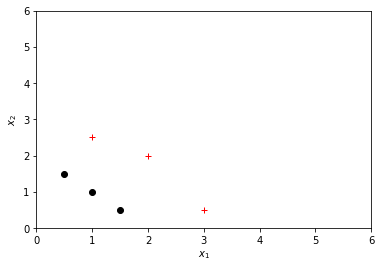

In [6]:
from lab_utils import plot_data
import matplotlib.pyplot as plt

plot_data(X,y)

# 把两个坐标轴都设为 0-6
plt.axis([0, 6, 0, 6])
# 设置 y 轴标签
plt.ylabel('$x_2$')
# 设置 x 轴标签
plt.xlabel('$x_1$')

## 梯度下降

 首先，你将实现梯度的非向量化版本。然后，你将实现向量化版本。


### 非向量化版本

回忆一下，在梯度下降中，每次迭代执行更新：

$$w_j :=w_j - \\alpha \\frac{\\partial J(\\mathbf{w})}{\\partial w_j} \\tag{1}$$ 

对所有 $j$ 同时更新 $w_j$，其中

$$ \\frac{\\partial J(\\mathbf{w})}{\\partial w_j}  = \\frac{1}{m} \\sum\\limits_{i = 1}^{m} (f_{\\mathbf{\\mathbf{w}}}(\\mathbf{x}^{(i)}) - y^{(i)})x_j^{(i)}\\tag{2}$$ 

- **注意**：虽然这个梯度看起来与线性回归的梯度完全相同，但公式实际上是不同的，因为线性回归和逻辑回归对 $f_w(x)$ 的定义不同。

你将在这个实验中实现 $\\frac{\\partial J(\\mathbf{w})}{\\partial w_j}$。
* m 是数据集中的训练样本数

    
*  $f_{\\mathbf{w}}(x^{(i)})$ 是模型的预测，而 $y^{(i)}$ 是实际标签

* 对于上面给定数据集的逻辑回归模型，模型可以表示为：

    $f_{\\mathbf{w}}(x) = g(w_0 + w_1x_1 + w_2x_2)$

    其中 $g(z)$ 是 sigmoid 函数：

    $g(z) = \\frac{1}{1+e^{-z}}$ 
    
    
* **预处理步骤**

   为便于实现，我们给 $X$ 增加一列全为 1 的列（作为 $x_0$），从而  
    $f_{\\mathbf{w}}(x) = g(w_0x_0 + w_1x_1 + w_2x_2)$
    
    这样，要计算模型的预测 $f_{\\mathbf{w}}(x)$，我们可以写一个 for 循环，在每一步计算 $w_jx_j$

In [7]:
# 给 X_orig 加一列以对应 w_0 项
X_mod = np.hstack([np.ones((X.shape[0],1)), X])

print(X_mod)

[[1.  0.5 1.5]
 [1.  1.  1. ]
 [1.  1.5 0.5]
 [1.  3.  0.5]
 [1.  2.  2. ]
 [1.  1.  2.5]]


#### 补充说明：sigmoid 函数的实现
我们已经为你实现了 `sigmoid` 函数，你只需导入并使用它，如下面的代码块所示。

In [8]:
from lab_utils import sigmoid 

print(sigmoid(0))

0.5


#### 实现

现在，你将实现梯度的非向量化版本。我们已经为你提供了一些起始代码，它完成了以下工作——
* 我们创建一个与 $w$ 形状相同的数组来存放梯度（名为 `dw`），并用零初始化。我们将更新并返回 `dw`
* 有一个 for 循环，在每次迭代中计算 `dw[j]`
* 每次迭代中，我们可以使用上面的梯度公式，其中还包含对数据集中所有样本的另一层 for 循环
* 我们把每个样本的梯度值存进一个列表，然后梯度 `dw[j]` 等于各样本梯度之和除以样本数

我们假定该函数接收的参数 $w$ 是列表/数组。

**练习**

你将在内层 for 循环内实现以下步骤来完成代价函数——

* 首先，按下所示计算索引为 $i$ 的单个数据点的模型预测 $f_\\mathbf{w}(\\mathbf{x}^{(i)})$

   
```
   z = 0
   for j in range(n):
       z += w[j] * X[i][j]
   f = sigmoid(z)
   ```

   
   由于 $w_0x_0 + w_1x_1+w_2x_2 = \\mathbf{w}\\cdot \\mathbf{x}$，你也可以这样计算 $f_\\mathbf{w}(\\mathbf{x}^{(i)})$
   
```
   z = np.dot(w, X[i])
   f = sigmoid(z)
   ```


* 然后，计算索引为 $i$ 的单个数据点的梯度，如下

  
```
  gradient = (f-y[i])*X[i][j] 
  ```



In [16]:
def compute_gradient(X, y, w):
    # 这里假定 X 已经过预处理，加了一列 1 作为 x_0
    m, n = X.shape
    dw = np.zeros_like(w)
    
    for j in range(n):
        gradient_list = []
        
        for i in range(m):        
            ### 在此处编写代码 ###

            ### 代码编写结束 ###
            gradient_list.append(gradient)
        
        dw[j] = (1/m)* sum(gradient_list)
        
    return dw

用下面的单元格检查你梯度函数的实现。

In [17]:
w = np.zeros(3)
compute_gradient(X_mod,y,w)

array([ 0.        , -0.25      , -0.16666667])

**预期输出**

array([ 0.        , -0.25      , -0.16666667])

### （可选）向量化版本

现在你将实现梯度函数的向量化版本。

梯度向量化版本的公式为

$$\\frac{\\partial \\mathbf{J}(w_j)}{\\partial \\mathbf{w}} = \\frac{1}{m} \\mathbf{X^T}(\\mathbf{f} - \\mathbf{y})$$ 

其中

$$ \\mathbf{f} = g(\\mathbf{X}  \\mathbf{w})$$

和之前一样，$g$ 是 sigmoid 函数


**练习**

你将实现以下步骤来完成向量化的代价函数——

* 首先，按下所示计算模型的预测 $f(x)$

   
```
   z = np.dot(X, w)
   f = sigmoid(z)
   ```

  

* 然后，按下式计算梯度

  
```
  dw = (1/m)*np.matmul(X.T, (f - y))
  ```



**调试提示：** 向量化代码有时会比较棘手。一个常用的调试策略是用 size 函数打印出所操作矩阵的尺寸。例如，给定大小为 6 × 3 的数据矩阵 $\\mathbf{X}$（6 个样本、3 个特征）和维度为 3x1 的向量 $\\mathbf{w}$，你可以发现 $\\mathbf{Xw}$ 是合法的乘法运算，而 $\\mathbf{wX}$ 不是。

In [23]:
def compute_gradient_vectorized(X, y, w):
    
    m, n = X.shape
    
    ### 在此处编写代码 ###

    ### 在此处编写代码 ###
    return dw

现在让我们检查这个函数的输出是否等价于上面非向量化实现的输出。

In [24]:
print("Cost computed by non-vectorized version: ", compute_gradient(X_mod, y, w))
print("Cost computed by vectorized version: ", compute_gradient_vectorized(X_mod, y, w))

Cost computed by non-vectorized version:  [ 0.         -0.25       -0.16666667]
Cost computed by vectorized version:  [ 0.         -0.25       -0.16666667]


**预期输出**

非向量化版本计算的代价：  [ 0.         -0.25       -0.16666667]

向量化版本计算的代价：  [ 0.         -0.25       -0.16666667]
